# 05 · Caso 2 — otimização: produção máxima e projeto ótimo do sistema de gas lift

Reprodução da Seção 6.2 do artigo: Tabelas 14 e 15 (produção máxima para reservatórios a
220 e 240 bar) e Tabelas 16–19 (projeto ótimo com custos anualizados de compressor, turbina,
linhas de gás e gás combustível). As variáveis de decisão do projeto são as vazões de óleo e
gás de cada poço e o diâmetro das linhas de gás de cada poço (12 variáveis).

Os problemas são os do bloco `study.optimizations` de `cases/case2_multi_well.json`; as
tabelas mostram os valores recalculados ao lado dos impressos no artigo.

Referência: de Souza, J.N.M., de Medeiros, J.L., Costa, A.L.H., Nunes, G.C. (2010).
*Modeling, simulation and optimization of continuous gas lift systems for deepwater
offshore petroleum production*. Journal of Petroleum Science and Engineering 72 (3–4),
277–289, doi:10.1016/j.petrol.2010.03.028.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
REF = ROOT / "data" / "reference"
published = json.load(open(REF / "published_tables.json"))   # Tables 13-19 as printed in the paper
pd.set_option("display.precision", 4)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 100, "figure.figsize": (7, 5), "axes.grid": True, "grid.alpha": 0.3})

In [2]:
from gaslift import tables
from gaslift.cases import load_case
from gaslift.economics import CostModel, CompressorParameters
from gaslift.study import build_problem, initial_vector, load_reference, optimization_record

case = load_case("case2")
matlab = load_reference("matlab_optimization_results.json")
specs = {s["name"]: s for s in case.study["optimizations"]}
records, results = {}, {}
PI = [r["productivity_index"] for r in specs["table14_maxprod_220bar"]["reservoirs"]]

def optimise(name):
    spec = specs[name]
    prob = build_problem(case, spec)
    t0 = time.perf_counter()
    res = prob.solve(initial_vector(prob, spec, records))
    records[name] = optimization_record(name, spec, res, time.perf_counter() - t0, matlab.get(spec.get("reference")))
    results[name] = res
    print(f"{name}: {res.n_evaluations} simulations in {time.perf_counter() - t0:.0f} s; total oil {res.oil_rates.sum():.3f} kg/s, profit {res.economics.profit:.3f} 10⁶ USD/yr")
    return res

## 6.2.1 · Produção máxima (Tabelas 14 e 15)

In [3]:
optimise("table14_maxprod_220bar")
optimise("table15_maxprod_240bar")

table14_maxprod_220bar: 851 simulations in 18 s; total oil 18.486 kg/s, profit 220.652 10⁶ USD/yr


table15_maxprod_240bar: 146 simulations in 4 s; total oil 23.675 kg/s, profit 282.597 10⁶ USD/yr


OptimizationResult(x=array([5.41610909, 6.42289352, 6.56102108, 5.27535922, 0.68129489,
       0.74489454, 0.82013063, 0.73666886]), objective=-282.5972276267106, success=True, message='Optimization terminated successfully', n_evaluations=146, n_iterations=16, solution=NetworkSolution(Network(name='Case 2 - offshore multiple wells', nodes=28, pipes=27, wells=4), converged (residual below tolerance) after 2 iterations, |F| = 1.427e-11, 0.03 s), economics=EconomicEvaluation(oil_rate=array([5.41610909, 6.42289352, 6.56102108, 5.27535922]), gas_rate=array([0.68129489, 0.74489454, 0.82013063, 0.73666886]), downhole_pressure=array([234.58401129, 237.43089164, 233.43905045, 229.44932425]), discharge_pressure=249.02954593045393, compressor_power=1761.3644034471433, oil_volume=array([1.26389982, 1.4988424 , 1.53107576, 1.23105451]), injected_gas_volume=array([17.9044296 , 19.57582861, 21.55303306, 19.35965767]), fuel_gas_volume=0.0, revenue=282.5972276267106, fuel_gas_cost=0.0, injected_gas_cos

In [4]:
tables.table14_15(records["table14_maxprod_220bar"], published["table14"], PI).rename_axis("Table 14 — 220 bar")

Well,1,2,3,4
Table 14 — 220 bar,,,,
Node,7.0000,13.0000,19.0000,25.0000
Productivity index ((kg/s)/bar),1.0000,2.5000,1.0000,0.5000
Downhole pressure (bar),215.7910,218.0281,214.8511,211.6051
Downhole pressure (bar) paper,215.8000,218.0300,214.8500,211.6100
Produced oil (kg/s),4.2095,4.9297,5.1489,4.1976
Produced oil (kg/s) paper,4.2040,4.9330,5.1520,4.1970
Injected gas (kg/s),0.7445,0.8209,0.8958,0.7947
Injected gas (kg/s) paper,0.7430,0.8220,0.8970,0.7950


In [5]:
tables.table14_15(records["table15_maxprod_240bar"], published["table15"], PI).rename_axis("Table 15 — 240 bar")

Well,1,2,3,4
Table 15 — 240 bar,,,,
Node,7.0000,13.0000,19.0000,25.0000
Productivity index ((kg/s)/bar),1.0000,2.5000,1.0000,0.5000
Downhole pressure (bar),234.5840,237.4309,233.4391,229.4493
Downhole pressure (bar) paper,234.5800,237.4300,233.4400,229.4500
Produced oil (kg/s),5.4161,6.4229,6.5610,5.2754
Produced oil (kg/s) paper,5.4170,6.4230,6.5610,5.2760
Injected gas (kg/s),0.6813,0.7449,0.8201,0.7367
Injected gas (kg/s) paper,0.6810,0.7440,0.8200,0.7340


Observações do artigo que podem ser verificadas acima: (1) para poços de mesmo índice de
produtividade e geometria semelhante (1 e 3), o poço mais próximo da plataforma recebe mais
gás e produz mais; (2) para distâncias semelhantes (3 e 4), mais gás vai ao poço de maior
índice; (3) a 240 bar produz-se mais óleo com menos gás injetado.

## 6.2.2 · Projeto ótimo (Tabelas 16–19)

Função objetivo $\Omega_3 = R - AGC - ATCC$. As estimativas iniciais são as soluções de
produção máxima acima, com linhas de gás de 2 in. Limites: diâmetros entre 1 e 4 in.
A Tabela 16 reúne os parâmetros de projeto usados (o coeficiente politrópico do compressor é
1,4, e não 1,25 como impresso — `docs/errata.md`, item A6).

In [6]:
comp = CompressorParameters()
cost = CostModel()
pub16 = published["table16"]["rows"]
table16 = pd.DataFrame({"gaslift": {
    "Number of compressor stages (n)": comp.stages, "Overall compressor efficiency (η)": comp.efficiency,
    "Polytropic coefficient used in Eq. 31 (γ)": comp.polytropic_exponent, "Suction temperature (K)": comp.suction_temperature,
    "Suction pressure (bar)": comp.suction_pressure, "Molecular weight (kg/kmol)": comp.molecular_weight,
    "Fuel gas cost (USD/Nm³)": cost.gas_price, "Oil price (USD/barrel)": cost.oil_price,
    "Pipe length LG1, LG2 (m)": case.gas_line_length("well_1"), "Pipe length LG3, LG4 (m)": case.gas_line_length("well_3"),
    "Diameter bounds (in)": str(specs["table17_19_design_220bar"]["diameter_bounds"]), "Productivity indexes": str(PI), "Reservoir pressure scenarios (bar)": "220, 240"},
    "paper (Table 16)": {
    "Number of compressor stages (n)": pub16["compressor_stages"], "Overall compressor efficiency (η)": pub16["compressor_efficiency"],
    "Polytropic coefficient used in Eq. 31 (γ)": pub16["polytropic_coefficient_printed"], "Suction temperature (K)": pub16["suction_temperature_K"],
    "Suction pressure (bar)": pub16["suction_pressure_bar"], "Molecular weight (kg/kmol)": pub16["molecular_weight_kg_kmol"],
    "Fuel gas cost (USD/Nm³)": pub16["fuel_gas_cost_usd_m3"], "Oil price (USD/barrel)": pub16["oil_price_usd_bbl"],
    "Pipe length LG1, LG2 (m)": pub16["gas_line_length_m"][0], "Pipe length LG3, LG4 (m)": pub16["gas_line_length_m"][2],
    "Diameter bounds (in)": str(pub16["diameter_bounds_in"]), "Productivity indexes": str(pub16["productivity_index"]), "Reservoir pressure scenarios (bar)": "220, 240"}})
table16.rename_axis("Table 16 — design parameters")

,gaslift,paper (Table 16)
Table 16 — design parameters,,
Number of compressor stages (n),3,3
Overall compressor efficiency (η),0.8,0.8
Polytropic coefficient used in Eq. 31 (γ),1.4,1.25
Suction temperature (K),300.0,300
Suction pressure (bar),5.0,5
Molecular weight (kg/kmol),25.0,25
Fuel gas cost (USD/Nm³),0.1886,0.189
Oil price (USD/barrel),51.15,51.15
"Pipe length LG1, LG2 (m)",6020.0126,6020


In [7]:
des220 = optimise("table17_19_design_220bar")
des240 = optimise("table17_19_design_240bar")

table17_19_design_220bar: 712 simulations in 39 s; total oil 18.470 kg/s, profit 210.816 10⁶ USD/yr


table17_19_design_240bar: 744 simulations in 25 s; total oil 23.660 kg/s, profit 273.257 10⁶ USD/yr


In [8]:
r1, r2 = records["table17_19_design_220bar"], records["table17_19_design_240bar"]
tables.table17(r1, r2, published).rename_axis("Table 17 — decision variables")

,Scenario 1,Scenario 1 (paper),Scenario 2,Scenario 2 (paper)
Table 17 — decision variables,,,,
Injected gas QG1 (kg/s),0.7052,0.706,0.6460,0.647
Injected gas QG2 (kg/s),0.7854,0.785,0.7095,0.709
Injected gas QG3 (kg/s),0.8547,0.854,0.7807,0.780
Injected gas QG4 (kg/s),0.7530,0.752,0.6974,0.697
Oil flow rate QL1 (kg/s),4.1924,4.197,5.4068,5.411
Oil flow rate QL2 (kg/s),4.9538,4.952,6.4457,6.444
Oil flow rate QL3 (kg/s),5.1518,5.152,6.5616,6.559
Oil flow rate QL4 (kg/s),4.1724,4.170,5.2459,5.246
Pipe diameter DG1 (in),1.7774,1.770,1.6485,1.660


In [9]:
tables.table18(r1, r2, published).rename_axis("Table 18 — pipelines, compressor and turbine")

,Scenario 1,Scenario 1 (paper),Scenario 2,Scenario 2 (paper),Unit
"Table 18 — pipelines, compressor and turbine",,,,,
Compressor power wC,1797.9929,1797.50,1692.8788,1691.10,kW
Compressor discharge pressure,235.3915,235.44,258.7780,258.02,bar
Compressor capital cost CC,1.7878,1.79,1.7222,1.72,10⁶ USD
Turbine capital cost CT,3.9476,3.95,3.7596,3.76,10⁶ USD
Gas pipelines capital cost CP,1.0535,1.05,0.9772,0.98,10⁶ USD
Fuel gas flow rate,15.1930,15.19,14.3048,14.29,10⁶ m³/yr


In [10]:
tables.table19(r1, r2, published).rename_axis("Table 19 — optimal design results")

,Scenario 1,Scenario 1 (paper),Scenario 2,Scenario 2 (paper),Unit
Table 19 — optimal design results,,,,,
Total injected gas flow rate,81.4247,81.39,74.4670,74.450,10⁶ m³/yr
Total oil flow rate,4.3103,4.31,5.5213,5.521,10⁶ barrel/yr
Fuel gas cost AGC,2.8651,2.86,2.6976,2.690,10⁶ USD/yr
Annualized capital cost,6.7888,6.79,6.4590,6.460,10⁶ USD/yr
ISBL,6.7888,6.79,6.4590,6.460,10⁶ USD
OSBL,20.3665,20.36,19.3770,19.380,10⁶ USD
Revenue R,220.4695,220.47,282.4134,282.410,10⁶ USD/yr
Profit,210.8155,210.82,273.2567,273.260,10⁶ USD/yr


As pequenas diferenças em relação ao MATLAB (terceira casa decimal) decorrem do otimizador:
a superfície do lucro é muito plana em torno do ótimo, e `fmincon` (2009) e SLSQP param em
pontos ligeiramente distintos com valores de função praticamente iguais. Os valores da
Tabela 18–19 avaliados exatamente nas variáveis de decisão publicadas reproduzem todos os
dígitos impressos (ver `gaslift eval`).

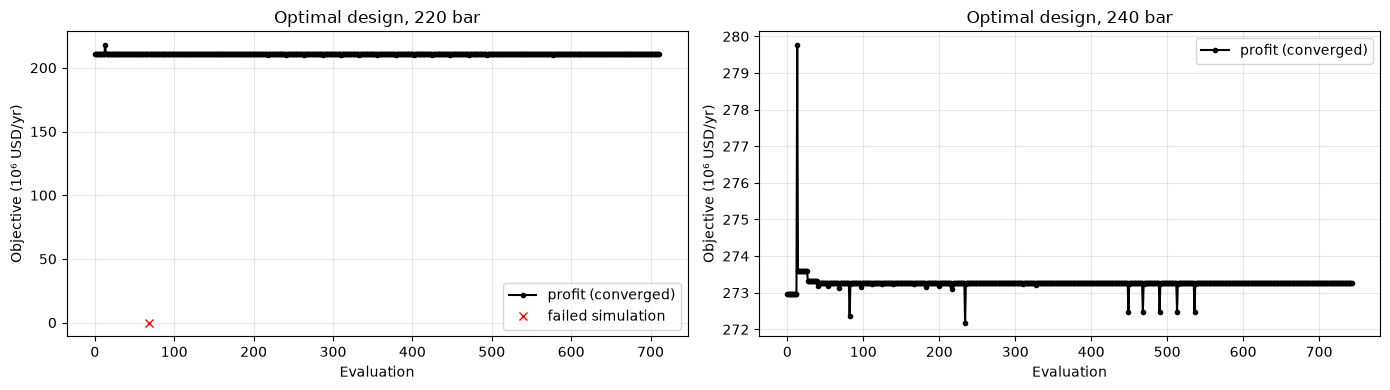

In [11]:
from gaslift.plotting import plot_optimization_history
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_optimization_history(des220.history, axes[0]); axes[0].set_title("Optimal design, 220 bar")
plot_optimization_history(des240.history, axes[1]); axes[1].set_title("Optimal design, 240 bar")
plt.tight_layout()